In [1]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

print("Librosa:", librosa.__version__)
print("NumPy:", np.__version__)
print("SoundFile:", sf.__version__)

print("Everything is working!")

Librosa: 1.0.0
NumPy: 2.5.2
SoundFile: 0.14.0
Everything is working!


In [3]:
import librosa

audio_path = "../MechanIQDataset/EngineKnock/ek1.wav"

audio, sample_rate = librosa.load(audio_path, sr=None)

print("Audio data:", audio)
print("Sample rate:", sample_rate)
print("Number of samples:", len(audio))
print("Duration:", len(audio) / sample_rate, "seconds")

Audio data: [ 0.          0.          0.         ... -0.15107727 -0.14489746
 -0.17790222]
Sample rate: 44100
Number of samples: 428032
Duration: 9.7059410430839 seconds


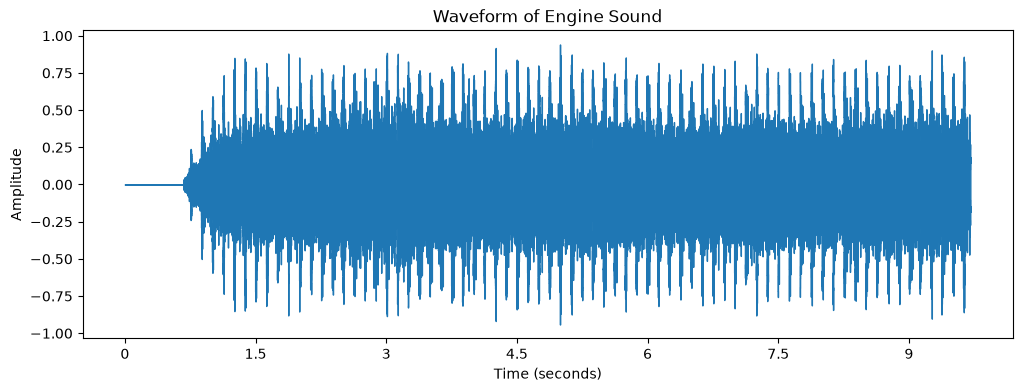

In [4]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

librosa.display.waveshow(audio, sr=sample_rate)

plt.title("Waveform of Engine Sound")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.show()

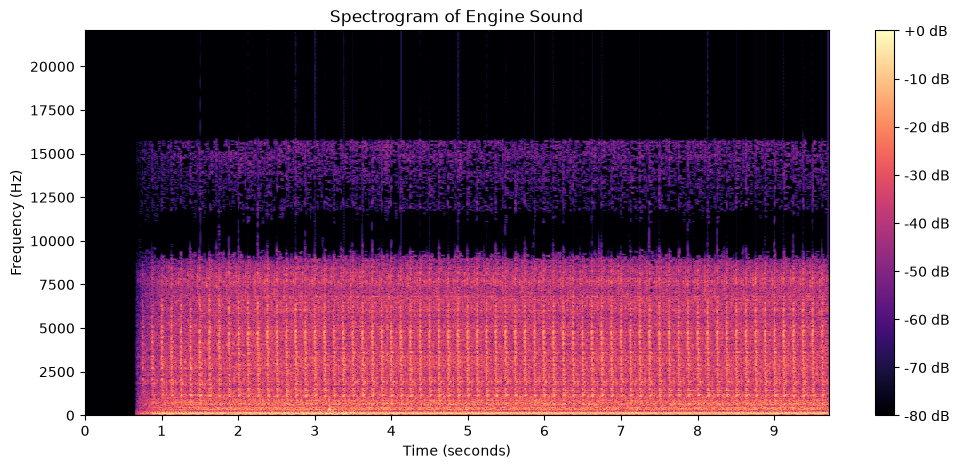

In [5]:
D = librosa.stft(audio)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    S_db,
    sr=sample_rate,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram of Engine Sound")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.show()

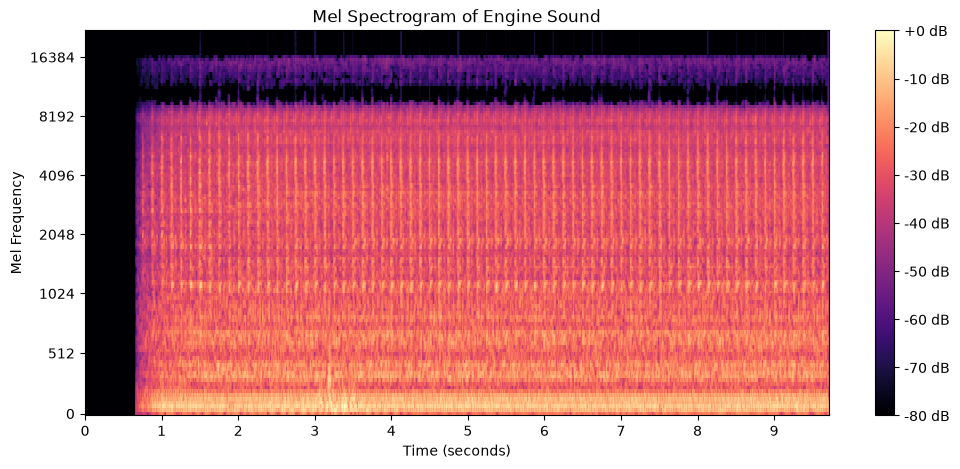

In [6]:
mel_spectrogram = librosa.feature.melspectrogram(
    y=audio,
    sr=sample_rate,
    n_mels=128,
    n_fft=2048,
    hop_length=512
)

mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mel_db,
    sr=sample_rate,
    hop_length=512,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram of Engine Sound")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")

plt.show()

In [7]:
print("Mel Spectrogram shape:", mel_db.shape)
print("Minimum value:", mel_db.min())
print("Maximum value:", mel_db.max())

Mel Spectrogram shape: (128, 837)
Minimum value: -80.0
Maximum value: 0.0


In [8]:
target_sr = 22050
target_duration = 5

audio_standardized, _ = librosa.load(
    audio_path,
    sr=target_sr,
    mono=True
)

target_samples = target_sr * target_duration

if len(audio_standardized) > target_samples:
    audio_standardized = audio_standardized[:target_samples]

elif len(audio_standardized) < target_samples:
    audio_standardized = librosa.util.fix_length(
        audio_standardized,
        size=target_samples
    )

print("Sample rate:", target_sr)
print("Number of samples:", len(audio_standardized))
print("Duration:", len(audio_standardized) / target_sr)

Sample rate: 22050
Number of samples: 110250
Duration: 5.0


In [9]:
from pathlib import Path

dataset_path = Path("../MechanIQDataset")

wav_files = list(dataset_path.rglob("*.wav"))

print("Number of recordings:", len(wav_files))

Number of recordings: 34


In [18]:
from pathlib import Path
import librosa
import soundfile as sf

dataset_path = Path("../MechanIQDataset")
output_path = Path("../StandardisedDataset")

output_path.mkdir(parents=True, exist_ok=True)

target_sr = 22050
target_duration = 5
target_samples = target_sr * target_duration

skipped_count = 0
processed_count = 0

wav_files = list(dataset_path.rglob("*.wav"))

print("Found", len(wav_files), "recordings")

for audio_path in wav_files:

    # Get class name from folder
    label = audio_path.parent.name

    # Create matching output folder
    label_output_path = output_path / label
    label_output_path.mkdir(parents=True, exist_ok=True)

    # Define output file BEFORE checking if it exists
    output_file = label_output_path / audio_path.name

    # Skip files that have already been standardised
    if output_file.exists():
        skipped_count += 1
        continue

    # Load and standardise sample rate + channels
    audio_standardized, _ = librosa.load(
        audio_path,
        sr=target_sr,
        mono=True
    )

    # Standardise duration
    if len(audio_standardized) > target_samples:

        audio_standardized = audio_standardized[:target_samples]

    elif len(audio_standardized) < target_samples:

        audio_standardized = librosa.util.fix_length(
            audio_standardized,
            size=target_samples
        )

    # Save standardised recording
    sf.write(
        output_file,
        audio_standardized,
        target_sr
    )

    processed_count += 1

    print("Processed:", audio_path.name, "→", label)


print()
print("Standardisation complete!")
print("Processed:", processed_count)
print("Skipped:", skipped_count)
print("Total:", processed_count + skipped_count)

Found 34 recordings

Standardisation complete!
Processed: 0
Skipped: 34
Total: 34


In [ ]:
import librosa
from pathlib import Path

standardized_files = list(
    output_path.rglob("*.wav")
)

print("Checking", len(standardized_files), "recordings...\n")

for audio_path in standardized_files:

    audio, sr = librosa.load(
        audio_path,
        sr=None,
        mono=True
    )

    duration = len(audio) / sr

    print(
        f"{audio_path.parent.name}/{audio_path.name} | "
        f"SR: {sr} | "
        f"Samples: {len(audio)} | "
        f"Duration: {duration:.2f}s"
    )

In [ ]:
from pathlib import Path
import librosa
import numpy as np

standardised_path = Path("../StandardisedDataset")
mel_output_path = Path("../MelSpectrogramDataset")

mel_output_path.mkdir(parents=True, exist_ok=True)

target_sr = 22050
n_mels = 128
n_fft = 2048
hop_length = 512

wav_files = list(standardised_path.rglob("*.wav"))

print("Found", len(wav_files), "standardised recordings")

processed_count = 0
skipped_count = 0

for audio_path in wav_files:

    # Get class name
    label = audio_path.parent.name

    # Create matching output folder
    label_output_path = mel_output_path / label
    label_output_path.mkdir(parents=True, exist_ok=True)

    # Change .wav to .npy
    output_file = label_output_path / f"{audio_path.stem}.npy"

    # Skip if Mel Spectrogram already exists
    if output_file.exists():
        skipped_count += 1
        print("Skipped:", audio_path.name)
        continue

    # Load standardised audio
    audio, sr = librosa.load(
        audio_path,
        sr=target_sr,
        mono=True
    )

    # Generate Mel Spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_mels=n_mels,
        n_fft=n_fft,
        hop_length=hop_length
    )

    # Convert power to decibels
    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # Save numerical Mel Spectrogram
    np.save(output_file, mel_db)

    processed_count += 1

    print("Created:", output_file.name, "→", label)


print()
print("Mel Spectrogram generation complete!")
print("Processed:", processed_count)
print("Skipped:", skipped_count)
print("Total:", processed_count + skipped_count)

In [20]:
from pathlib import Path
import numpy as np

mel_dataset_path = Path("../MelSpectrogramDataset")

npy_files = list(mel_dataset_path.rglob("*.npy"))

print("Number of Mel Spectrograms:", len(npy_files))

shapes = {}

for file in npy_files:
    mel = np.load(file)
    shape = mel.shape

    if shape not in shapes:
        shapes[shape] = []

    shapes[shape].append(file.name)

print("\nShapes found:")

for shape, files in shapes.items():
    print(shape, "→", len(files), "files")

Number of Mel Spectrograms: 34

Shapes found:
(128, 216) → 34 files


In [21]:
from pathlib import Path
import numpy as np

mel_dataset_path = Path("../MelSpectrogramDataset")

X = []
y = []
file_paths = []

class_names = sorted([
    folder.name
    for folder in mel_dataset_path.iterdir()
    if folder.is_dir()
])

print("Classes:")
for index, class_name in enumerate(class_names):
    print(index, "→", class_name)

for class_index, class_name in enumerate(class_names):

    class_path = mel_dataset_path / class_name

    for file in sorted(class_path.glob("*.npy")):

        mel = np.load(file)

        X.append(mel)
        y.append(class_index)
        file_paths.append(file)

X = np.array(X)
y = np.array(y)

print()
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of files:", len(file_paths))

Classes:
0 → BrakeSqueal
1 → CVJoints
2 → EngineKnock
3 → SerpentineBelt
4 → StarterAlternator
5 → WheelBearing

X shape: (34, 128, 216)
y shape: (34,)
Number of files: 34


In [27]:
import numpy as np

# ==========================================
# Lists to store our three datasets
# ==========================================

X_train = []
y_train = []
paths_train = []

X_val = []
y_val = []
paths_val = []

X_test = []
y_test = []
paths_test = []


# ==========================================
# Split each class separately
# ==========================================

for class_index, class_name in enumerate(class_names):

    # Get positions of all recordings belonging to this class
    class_indices = np.where(y == class_index)[0]

    # Shuffle the recordings for this class
    rng = np.random.default_rng(42)
    rng.shuffle(class_indices)

    # Number of recordings in this class
    class_count = len(class_indices)


    # ==========================================
    # Decide how many go into each set
    # ==========================================

    # Always keep 1 for validation
    # Always keep 1 for testing
    # Everything else goes to training

    test_count = 1
    val_count = 1
    train_count = class_count - val_count - test_count


    # ==========================================
    # Get the indices
    # ==========================================

    train_indices = class_indices[:train_count]

    val_indices = class_indices[
        train_count:train_count + val_count
    ]

    test_indices = class_indices[
        train_count + val_count:
    ]


    # ==========================================
    # Add recordings to each dataset
    # ==========================================

    for index in train_indices:

        X_train.append(X[index])
        y_train.append(y[index])
        paths_train.append(file_paths[index])


    for index in val_indices:

        X_val.append(X[index])
        y_val.append(y[index])
        paths_val.append(file_paths[index])


    for index in test_indices:

        X_test.append(X[index])
        y_test.append(y[index])
        paths_test.append(file_paths[index])


# ==========================================
# Convert lists to NumPy arrays
# ==========================================

X_train = np.array(X_train)
y_train = np.array(y_train)

X_val = np.array(X_val)
y_val = np.array(y_val)

X_test = np.array(X_test)
y_test = np.array(y_test)


# ==========================================
# Display final sizes
# ==========================================

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print()

print("Validation set:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print()

print("Test set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print()

print("Total recordings:", len(X_train) + len(X_val) + len(X_test))

Training set:
X_train: (22, 128, 216)
y_train: (22,)

Validation set:
X_val: (6, 128, 216)
y_val: (6,)

Test set:
X_test: (6, 128, 216)
y_test: (6,)

Total recordings: 34


In [25]:
print("TRAINING SET")
print("==============================")

for class_index, class_name in enumerate(class_names):
    count = np.sum(y_train == class_index)
    print(class_index, "→", class_name, ":", count)


print("\nVALIDATION SET")
print("==============================")

for class_index, class_name in enumerate(class_names):
    count = np.sum(y_val == class_index)
    print(class_index, "→", class_name, ":", count)


print("\nTEST SET")
print("==============================")

for class_index, class_name in enumerate(class_names):
    count = np.sum(y_test == class_index)
    print(class_index, "→", class_name, ":", count)

TRAINING SET
0 → BrakeSqueal : 3
1 → CVJoints : 3
2 → EngineKnock : 4
3 → SerpentineBelt : 3
4 → StarterAlternator : 4
5 → WheelBearing : 5

VALIDATION SET
0 → BrakeSqueal : 1
1 → CVJoints : 1
2 → EngineKnock : 1
3 → SerpentineBelt : 1
4 → StarterAlternator : 1
5 → WheelBearing : 1

TEST SET
0 → BrakeSqueal : 1
1 → CVJoints : 1
2 → EngineKnock : 1
3 → SerpentineBelt : 1
4 → StarterAlternator : 1
5 → WheelBearing : 1


In [28]:
import numpy as np

# ==========================================
# Normalise Mel Spectrogram values
# ==========================================
# Current values are approximately -80 dB to 0 dB.
# We convert them to a range of 0 to 1.

X_train = (X_train + 80) / 80
X_val = (X_val + 80) / 80
X_test = (X_test + 80) / 80


# ==========================================
# Add CNN channel dimension
# ==========================================
# CNN expects:
# (samples, height, width, channels)
#
# Our spectrograms are:
# (samples, 128, 216)
#
# Therefore we add one channel.

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]


# ==========================================
# Display results
# ==========================================

print("Training data:")
print("Shape:", X_train.shape)
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print()

print("Validation data:")
print("Shape:", X_val.shape)
print("Minimum:", X_val.min())
print("Maximum:", X_val.max())

print()

print("Test data:")
print("Shape:", X_test.shape)
print("Minimum:", X_test.min())
print("Maximum:", X_test.max())

Training data:
Shape: (22, 128, 216, 1)
Minimum: 0.0
Maximum: 1.0

Validation data:
Shape: (6, 128, 216, 1)
Minimum: 0.0
Maximum: 1.0

Test data:
Shape: (6, 128, 216, 1)
Minimum: 0.0
Maximum: 1.0


In [30]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# ==========================================
# MECHANIQ CNN MODEL
# ==========================================

model = keras.Sequential([

    # --------------------------------------
    # Input
    # --------------------------------------
    # Mel Spectrogram:
    # 128 frequency bins
    # 216 time frames
    # 1 channel
    layers.Input(shape=(128, 216, 1)),


    # --------------------------------------
    # Convolution Block 1
    # --------------------------------------
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),


    # --------------------------------------
    # Convolution Block 2
    # --------------------------------------
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),


    # --------------------------------------
    # Reduce feature maps
    # --------------------------------------
    layers.GlobalAveragePooling2D(),


    # --------------------------------------
    # Fully connected layer
    # --------------------------------------
    layers.Dense(
        32,
        activation="relu"
    ),


    # --------------------------------------
    # Output layer
    # --------------------------------------
    # 6 vehicle fault classes
    layers.Dense(
        6,
        activation="softmax"
    )
])




model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# DISPLAY MODEL


model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 214, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 107, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 105, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 52, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,094 (82.40 KB)

 Trainable params: 21,094 (82.40 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


from tensorflow.keras.callbacks import EarlyStopping


# Stop training if validation loss
# stops improving.

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)


history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=50,

    callbacks=[
        early_stopping
    ],

    verbose=1
)

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1364 - loss: 1.7972 - val_accuracy: 0.1667 - val_loss: 1.7984
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step - accuracy: 0.2273 - loss: 1.7902 - val_accuracy: 0.1667 - val_loss: 1.8006
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.2273 - loss: 1.7873 - val_accuracy: 0.1667 - val_loss: 1.8023
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step - accuracy: 0.2273 - loss: 1.7857 - val_accuracy: 0.1667 - val_loss: 1.8025
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.2273 - loss: 1.7834 - val_accuracy: 0.1667 - val_loss: 1.8019
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.2273 - loss: 1.7811 - val_accuracy: 0.1667 - val_loss: 1.8015
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.2273 - loss: 1.7788 - val_accuracy: 0.1667 - val_loss: 1.8018
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.2273 - loss: 1.7767 - val_accuracy: 0.3333 - val_loss: 1.